# dc SQUID readout chains

In lumped-element experiments, a dc SQUID converts flux from a tuned axion pickup into an electrical output. Its measurement noise is correlated with circulating-current noise that feeds back into the pickup. An array and preamplifier add further noise. In this tutorial we follow the chain through resonator coupling and scan reach. The chain models (`axionfem.squid`) are beta.

## Noise parameters

For one-sided per-Hz power spectral densities,

$$
\eta(\omega)=
\frac{\sqrt{S^{(1)}_{\Phi,\rm tot}S^{(1)}_J-(S^{(1)}_{\Phi J})^2}}{\hbar},
\qquad
\epsilon_{\rm uc}(\omega)=\frac{S^{(1)}_{\Phi,\rm tot}}{2L_{\rm sq}}.
$$

The spectra describe total flux noise, first-stage circulating-current noise, and their real cross-spectrum. $L_{\rm sq}$ is the first-stage loop inductance; $\omega$ is angular frequency. Dimensionless $\eta$ accounts for correlation; $\epsilon_{\rm uc}$ is uncoupled energy sensitivity in joule-seconds. Smaller $\eta$ improves scan sensitivity at fixed detector and thermal noise.

We import the readout and scan tools and set plotting defaults for the calculations below.

In [1]:
import math, sys, tempfile, warnings, dataclasses
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

try:
    import axionfem as af
except ImportError:                       # running from a source checkout without installing
    sys.path.insert(0, str(Path.cwd().parent / "python"))
    import axionfem as af

from axionfem import squid, scan, circuit as ck
from axionfem.circuit import HBAR, KB, PHI0

print("axionFEM", af.__version__)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "lines.linewidth": 1.8, "legend.frameon": False})

# One colour per second-stage bandwidth (the entity), fixed across all figures;
# line style = amplifier (solid: RT preamps, dashed: cryogenic RF amp).
COL = {"low": "#2a78d6", "medium": "#eb6834", "high": "#1baf7a", "C1": "#6250d6", "ideal": "0.15"}

axionFEM 0.1.0


The schematic shows junctions, shunts, input coil and mutual inductance. Its helper requires running from `examples/` in a source checkout.

We check the model formulas and display the first-stage schematic to show the circuit elements.

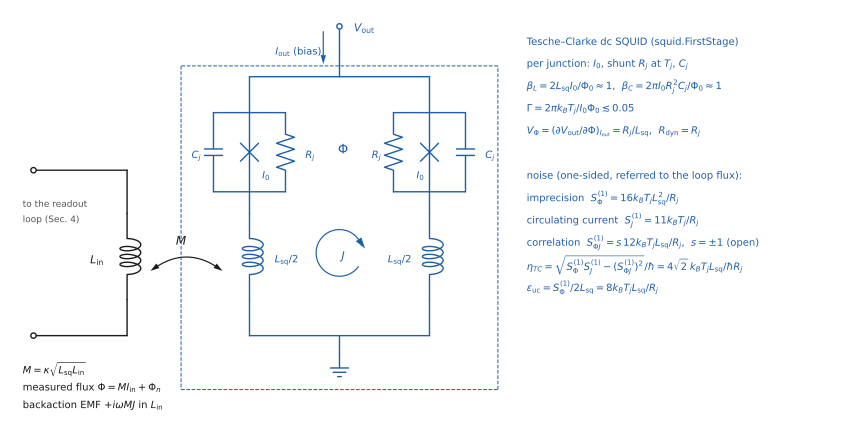

In [2]:
import importlib.util
try:
    import schemdraw  # noqa: F401
    spec = importlib.util.spec_from_file_location("make_circuit_figure",
                                                  Path.cwd().parent / "docs" / "images" / "make_circuit_figure.py")
    mcf = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(mcf)
    mcf.check_model()                      # the printed formulas agree with axionfem.squid
    display(mcf.first_stage())
except ImportError:
    print("schemdraw is not installed: pip install 'axionfem[draw]' to see the drawing "
          "(or open docs/images/squid_first_stage.svg)")

## Presets

`C1` is the first stage alone. `C1+low+RT` adds a 48-by-3 SQUID array and room-temperature preamplifier. We tabulate $\eta$, $\epsilon_{\rm uc}/\hbar$, and noise with correlation removed to compare the presets.

In [3]:
print(squid.presets())
print()
print(f"{'preset':<16}{'f [MHz]':>9}{'eta':>9}{'eps_uc/hbar':>13}{'eta (no corr.)':>16}")
for p in squid.presets():
    ch = squid.chain(p)
    for f in ((1e6, 100e6) if "cryo" not in p else (10e6, 100e6)):
        print(f"{p:<16}{f/1e6:>9g}{ch.eta(f):>9.3f}{ch.eps_uc_over_hbar(f):>13.3f}{ch.eta_uncorrelated(f):>16.3f}")

['C1', 'C1+low+RT', 'C1+low+cryo', 'C1+medium+RT', 'C1+medium+cryo', 'C1+high+RT', 'C1+high+cryo']

preset            f [MHz]      eta  eps_uc/hbar  eta (no corr.)
C1                      1    3.703        5.237           8.684
C1                    100    3.703        5.237           8.684
C1+low+RT               1    9.707       10.828          12.488
C1+low+RT             100   24.446       45.782          25.677
C1+low+cryo            10    5.782        6.606           9.754
C1+low+cryo           100   10.745       12.302          13.310
C1+medium+RT            1   13.958       17.813          16.017
C1+medium+RT          100   23.102       41.344          24.401
C1+medium+cryo         10    7.530        8.222          10.881
C1+medium+cryo        100   10.214       11.529          12.885
C1+high+RT              1   27.168       55.538          28.281
C1+high+RT            100   34.270       85.837          35.159
C1+high+cryo           10   13.566       17.065          15.676
C1+h

We report the array time constant and first-stage diagnostics to check the operating regime.

In [4]:
low = squid.chain("C1+low+RT")
print(low.label)
print(f"L2 = {low.second.L2_H*1e9:.2f} nH, tau = {low.tau_s*1e9:.2f} ns")
v = squid.C1.validity()
print({k: (round(v[k], 4) if isinstance(v[k], float) else v[k])
       for k in ("beta_L", "beta_C", "Gamma", "f_josephson_Hz", "beta_C_checked", "warnings") if k in v})
print(f"C1: eta_TC = {squid.C1.eta_TC:.3f}, eps_uc/hbar = {squid.C1.eps_uc_J_s/HBAR:.3f}, "
      f"real-source (on-resonance) match = {squid.C1.on_resonance_over_SQL:.2f} x SQL")

C1 + low BW 48x3 + RT (XXF-1 < 50 MHz, 300 MHz preamp above)
L2 = 20.00 nH, tau = 3.33 ns
{'beta_L': 1.2187, 'beta_C': nan, 'Gamma': 0.001, 'f_josephson_Hz': 6946399496.2133, 'beta_C_checked': False, 'warnings': []}
C1: eta_TC = 3.703, eps_uc/hbar = 5.237, real-source (on-resonance) match = 8.68 x SQL


## Custom devices

We set junction and loop parameters, then attach the later stages. `validity()` reports junction and thermal diagnostics; the Tesche–Clarke model assumes weak coupling and optimal bias. It omits $1/f$ and quantum noise, later-stage backaction, and SQUID input loading.

We evaluate custom chains and a hot-shunt device to compare noise and check operating-regime warnings.

In [5]:
dev = squid.FirstStage(L_sq_H=80e-12, I0_A=12e-6, R_j_ohm=3.0, T_j_K=0.10, C_j_F=3.0e-12, label="my SQUID")
vd = dev.validity()
print(f"beta_L = {vd['beta_L']:.2f}, beta_C = {vd['beta_C']:.2f}, Gamma = {vd['Gamma']:.1e}, "
      f"f_J = {dev.f_josephson_Hz/1e9:.1f} GHz, warnings: {vd['warnings']}")
print(f"eta_TC = {dev.eta_TC:.3f}   eps_uc/hbar = {dev.eps_uc_J_s/HBAR:.3f}")

mine = squid.Chain(dev, squid.SecondStage(48, 3, T2_K=1.0), squid.RT, label="my SQUID + 48x3 + RT")
# the same device through the preset machinery: replace C1 by `first=`
mine_cryo = squid.chain("C1+low+cryo", first=dev)
for f in (1e6, 10e6, 100e6):
    print(f"{f/1e6:6g} MHz  eta = {mine.eta(f):7.3f}   eps_uc/hbar = {mine.eps_uc_over_hbar(f):7.3f}   "
          f"(cryo amp: eta = {mine_cryo.eta(f) if f >= 5e6 else float('nan'):7.3f})")

# A warning example: the same SQUID with hot shunts (Gamma > 0.05 leaves the TC regime)
with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    squid.FirstStage(L_sq_H=80e-12, I0_A=1e-6, R_j_ohm=3.0, T_j_K=4.2)
print("hot device ->", [str(x.message)[:110] + "..." for x in w])

beta_L = 0.93, beta_C = 0.98, Gamma = 3.5e-04, f_J = 6.6 GHz, warnings: []
eta_TC = 1.975   eps_uc/hbar = 2.793
     1 MHz  eta =   4.594   eps_uc/hbar =   5.032   (cryo amp: eta =     nan)
    10 MHz  eta =   4.908   eps_uc/hbar =   5.421   (cryo amp: eta =   2.939)
   100 MHz  eta =  20.803   eps_uc/hbar =  58.632   (cryo amp: eta =   8.868)
hot device -> ['squid.FirstStage(first stage): beta_L = 2 L I0/Phi0 = 0.0774 is outside [0.5, 2.0] (TC optimum ~ 1)...', 'squid.FirstStage(first stage): Gamma = 0.176 > 0.05: the TC noise coefficients 16/11/12 (Eqs. 5-7) assume Gamm...']


## Frequency dependence

Later stages increase imprecision at high frequency; RT preamplifiers switch at 50 MHz. Cryogenic curves begin at 5 MHz.

We plot both noise parameters against frequency to compare readout chains.

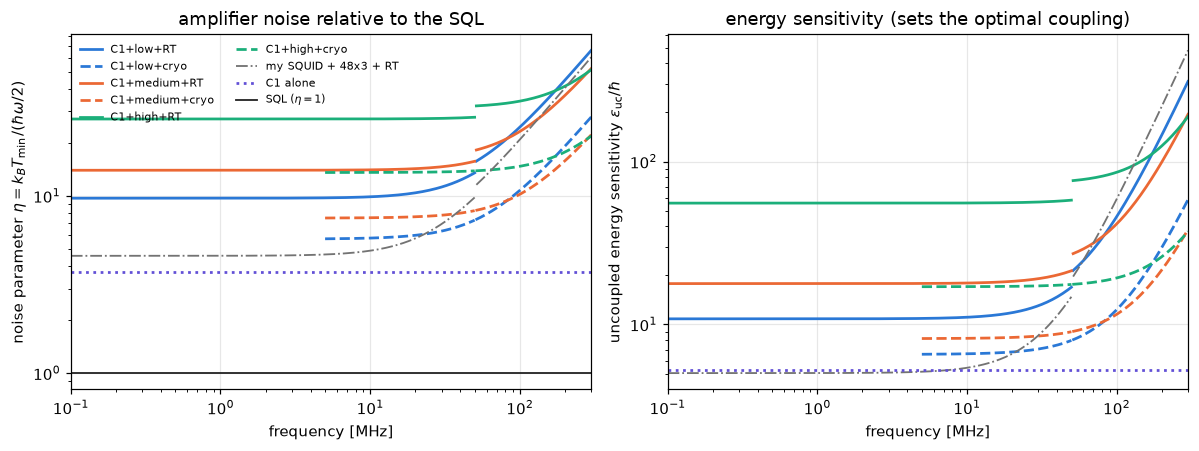

In [6]:
def curve(ch, f_lo, f_hi, n=300):
    # eta and eps_uc/hbar on a log grid; NaN at 50 MHz to break the line at the RT preamp switch
    f = np.geomspace(f_lo, f_hi, n)
    if f_lo < 50e6 < f_hi:
        f = np.concatenate([f[f < 50e6], [np.nan], f[f >= 50e6]])
    eta, eps = np.full(f.shape, np.nan), np.full(f.shape, np.nan)
    ok = np.isfinite(f)
    eta[ok], eps[ok] = ch.eta(f[ok]), ch.eps_uc_over_hbar(f[ok])
    return f, eta, eps

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
c1 = squid.chain("C1")
for bw in ("low", "medium", "high"):
    for amp, (a, b), ls in (("RT", (1e5, 3e8), "-"), ("cryo", (5e6, 3e8), "--")):
        f, eta, eps = curve(squid.chain(f"C1+{bw}+{amp}"), a, b)
        for ax, y in zip(axes, (eta, eps)):
            ax.plot(f / 1e6, y, color=COL[bw], ls=ls, label=f"C1+{bw}+{amp}")
f, eta, eps = curve(mine, 1e5, 3e8)
for ax, y in zip(axes, (eta, eps)):
    ax.plot(f / 1e6, y, color="0.45", lw=1.2, ls="-.", label="my SQUID + 48x3 + RT")
axes[0].axhline(c1.eta(1e6), color=COL["C1"], ls=":", label="C1 alone")
axes[1].axhline(c1.eps_uc_over_hbar(1e6), color=COL["C1"], ls=":", label="C1 alone")
axes[0].axhline(1.0, color=COL["ideal"], lw=1.2, label="SQL ($\\eta=1$)")
axes[0].set_ylabel(r"noise parameter $\eta = k_BT_{\min}/(\hbar\omega/2)$")
axes[1].set_ylabel(r"uncoupled energy sensitivity $\epsilon_{\rm uc}/\hbar$")
for ax in axes:
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(0.1, 300)
    ax.set_xlabel("frequency [MHz]")
axes[0].legend(fontsize=7, ncol=2, loc="upper left")
axes[0].set_title("amplifier noise relative to the SQL")
axes[1].set_title("energy sensitivity (sets the optimal coupling)")
fig.tight_layout()

We use `one_sided()` to compare each stage's contribution to the total flux-noise spectrum, referred to the first loop.

In [7]:
p = low.one_sided(1e6)
tc = float(p["S1_Phi_TC_Wb2_Hz"])
print(f"first stage (TC)       : {math.sqrt(tc)/PHI0*1e6:.3f} uPhi0/rtHz")
for k, v in p["S1_Phi_ref_parts_Wb2_Hz"].items():
    print(f"{k:<23}: {math.sqrt(float(v))/PHI0*1e6:.3f} uPhi0/rtHz (referred)")
print(f"total                  : {math.sqrt(float(p['S1_Phi_Wb2_Hz']))/PHI0*1e6:.3f} uPhi0/rtHz")

first stage (TC)       : 0.227 uPhi0/rtHz
second_stage_squid     : 0.105 uPhi0/rtHz (referred)
preamp_V_and_lead      : 0.196 uPhi0/rtHz (referred)
preamp_I               : 0.076 uPhi0/rtHz (referred)
total                  : 0.327 uPhi0/rtHz


## Coupling to a resonator

We specify the loaded quality factor, total inductance and noise temperature. `M_scan_H()` returns the mutual inductance in henries for maximum scan rate. We plot the coupling across frequency to compare this choice with noise matching at resonance.

at 1 MHz, 30 mK: n = 625, eta = 9.71, xi_opt = 0.0754, kappa_g^2 = 2.873e-04, M = 239.7 pH for L_tot = 1 uH


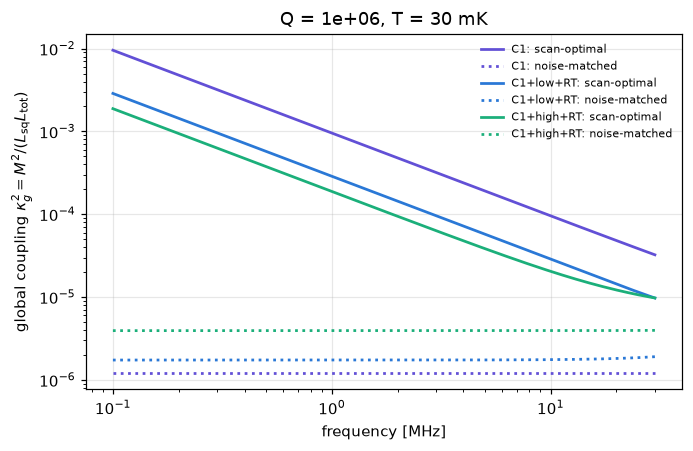

In [8]:
Q, T = 1e6, 0.03
f = np.geomspace(1e5, 3e7, 200)
fig, ax = plt.subplots(figsize=(6.4, 4.2))
for name, col in (("C1", COL["C1"]), ("C1+low+RT", COL["low"]), ("C1+high+RT", COL["high"])):
    ch = squid.chain(name)
    ax.plot(f / 1e6, ch.kappa_g2_scan(f, Q, T), color=col, label=f"{name}: scan-optimal")
    ax.plot(f / 1e6, ch.on_resonance(f, Q=Q)["kappa_g2_match"], color=col, ls=":",
            label=f"{name}: noise-matched")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("frequency [MHz]"); ax.set_ylabel(r"global coupling $\kappa_g^2 = M^2/(L_{\rm sq}L_{\rm tot})$")
ax.set_title(f"Q = {Q:.0e}, T = {T*1e3:.0f} mK")
ax.legend(fontsize=7)
fig.tight_layout()

ch = squid.chain("C1+low+RT")
n1 = ck.n_bose(2 * math.pi * 1e6, T)
print(f"at 1 MHz, 30 mK: n = {n1:.0f}, eta = {ch.eta(1e6):.2f}, xi_opt = {ch.xi_opt(1e6, T):.4f}, "
      f"kappa_g^2 = {ch.kappa_g2_scan(1e6, Q, T):.3e}, M = {ch.M_scan_H(1e6, Q, 1e-6, T)*1e12:.1f} pH for L_tot = 1 uH")

`M_scan_H()` raises for coupling beyond the global physical bound. The input coil should also be checked to ensure it can realize the returned mutual inductance.

We request coupling beyond the global bound to demonstrate the resulting error.

In [9]:
c1 = squid.chain("C1")
print("C1 at 100 kHz, Q = 1e3: kappa_g^2 =", round(float(c1.kappa_g2_scan(1e5, 1e3, 0.03)), 2))
try:
    c1.M_scan_H(1e5, 1e3, 1e-6, 0.03)
except ValueError as e:
    print("ValueError:", e)

C1 at 100 kHz, Q = 1e3: kappa_g^2 = 9.55
ValueError: squid: Eq. 48 asks for kappa_g^2 = 9.549 > 1, which no input transformer reaches (Eq. 21); the scan-optimal coupling is not attainable here


## Detector and readout

Mesh convergence should be checked for each geometry.

We solve a toroid for pickup inductance and signal coupling, then rescale the signal coupling for the target magnetic field.

In [10]:
d = af.template("toroid", R=1.0, H=1.0)
res = d.solve(tempfile.mkdtemp(prefix="axf_squid_nb_"), verbose=0)
B_target = 5.0
PSI = res.Psi * B_target / res.B_max
LP = res.L_p
print(f"solved: Psi = {res.Psi:.3e} H T m^2 at B_max = {res.B_max:.3f} T;  L_p = {LP:.3e} H")
print(f"rescaled to B_max = {B_target} T: Psi = {PSI:.3e} H T m^2")

solved: Psi = 7.703e-08 H T m^2 at B_max = 0.330 T;  L_p = 7.430e-07 H
rescaled to B_max = 5.0 T: Psi = 1.168e-06 H T m^2


`squid_for_resonator()` supplies a SQUID model at the optimal mutual inductance, holding chain noise at the tuning frequency and converting to the circuit's spectral convention.

We assemble a tuned series readout and attach its SQUID to evaluate the optimally coupled circuit.

In [11]:
f0, Q, T, L_in = 1e6, 1e6, 0.03, 2e-9
ro = ck.series_readout(L_p_H=LP, Psi_SI=PSI, f_Hz=f0, Q=Q, T_K=T, L_in_H=L_in, M_H=1e-9)
eq0 = ro.equivalent(f_Hz=f0)
w0, L_eff, QL, R0 = eq0["omega0_rad_s"], eq0["L_eff_H"], eq0["Q_loaded"], eq0["R_eff_ohm"]
print(f"f0 = {eq0['f0_Hz']:.6g} Hz, L_eff = {L_eff:.4e} H, Q_loaded = {QL:.4e}, R_eff = {R0:.3e} ohm")

chain_p = squid.chain("C1+low+RT", sign=+1)
ro.squid = chain_p.squid_for_resonator(f0, QL, L_eff, T)
sq = ro.squid
print(f"M = {sq.M_H*1e12:.1f} pH;  circuit PSDs: S_Phi = {sq.S_Phi:.3e} Wb^2 s, S_J = {sq.S_J:.3e} A^2 s, "
      f"S_PhiJ = {sq.S_PhiJ:+.3e} Wb A s;  eta_A = {sq.eta_A:.3f}")

eq = ro.equivalent(w0)
print(f"xi = {eq['xi']:.5f} (optimal {chain_p.xi_opt(f0, T):.5f});  eta_A_eff = {eq['eta_A_eff']:.3f}, "
      f"uncorrelated eta = {eq['eta_A_eff_uncorrelated']:.3f};  band shift x0 = {eq['band_shift_x0']:+.1f} half-linewidths")
print("noise-doubling bandwidth = %.1f Hz (resonator linewidth %.2f Hz)"
      % (eq["bandwidth_Hz"]["noise_doubling"], eq["bandwidth_Hz"]["linewidth"]))

f0 = 1e+06 Hz, L_eff = 7.4500e-07 H, Q_loaded = 1.0027e+06, R_eff = 4.668e-06 ohm
M = 206.6 pH;  circuit PSDs: S_Phi = 2.284e-43 Wb^2 s, S_J = 1.898e-24 A^2 s, S_PhiJ = +4.142e-34 Wb A s;  eta_A = 9.707
xi = 0.07537 (optimal 0.07537);  eta_A_eff = 9.707, uncorrelated eta = 12.488;  band shift x0 = +104.2 half-linewidths
noise-doubling bandwidth = 222.5 Hz (resonator linewidth 1.00 Hz)


We plot thermal noise, backaction, imprecision and correlation, all referred to a series voltage in the pickup, to compare their contributions.

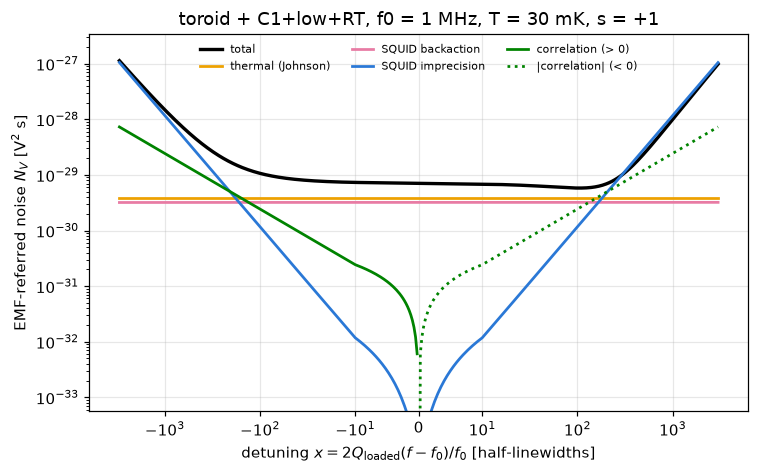

In [12]:
x = np.unique(np.concatenate([-np.geomspace(3000, 10, 250), np.linspace(-10, 10, 81), np.geomspace(10, 3000, 250)]))
w = w0 * (1 + x / (2 * QL))

def budget(readout):
    keys = ("N_V_V2_s", "N_V_thermal_V2_s", "N_V_backaction_V2_s", "N_V_imprecision_V2_s", "N_V_correlation_V2_s")
    out = {k: np.empty(w.size) for k in keys}
    for i, wi in enumerate(w):
        dd = readout.noise_psd(float(wi))
        for k in keys:
            out[k][i] = dd[k]
    return out

nb = budget(ro)
fig, ax = plt.subplots(figsize=(7, 4.4))
ax.plot(x, nb["N_V_V2_s"], color="k", lw=2.2, label="total")
ax.plot(x, nb["N_V_thermal_V2_s"], color="#eda100", label="thermal (Johnson)")
ax.plot(x, nb["N_V_backaction_V2_s"], color="#e87ba4", label="SQUID backaction")
ax.plot(x, nb["N_V_imprecision_V2_s"], color="#2a78d6", label="SQUID imprecision")
corr = nb["N_V_correlation_V2_s"]
ax.plot(x, np.where(corr > 0, corr, np.nan), color="#008300", label="correlation (> 0)")
ax.plot(x, np.where(corr < 0, -corr, np.nan), color="#008300", ls=":", label="|correlation| (< 0)")
ax.set_xscale("symlog", linthresh=10.0, linscale=0.6); ax.set_yscale("log")
ax.set_ylim(nb["N_V_V2_s"].min() / 1e4, nb["N_V_V2_s"].max() * 3)
ax.set_xlabel(r"detuning $x = 2Q_{\rm loaded}(f-f_0)/f_0$ [half-linewidths]")
ax.set_ylabel(r"EMF-referred noise $N_V$ [V$^2$ s]")
ax.set_title(f"toroid + C1+low+RT, f0 = {f0/1e6:g} MHz, T = {T*1e3:.0f} mK, s = +1")
ax.legend(fontsize=7, ncol=3, loc="upper center")
fig.tight_layout()

## Scan reach

We distribute three years uniformly in log frequency, adjusting coupling at each tuning. This assumes the required coupling can be realized throughout the band.

We compute and plot scan reach for the amplifier choices to compare their sensitivity.

ideal amplifier    g95 at  0.10 MHz = 8.263e-18 GeV^-1,  eta there = 1.00
C1 alone           g95 at  0.10 MHz = 1.146e-17 GeV^-1,  eta there = 3.70
C1+low+RT          g95 at  0.10 MHz = 1.459e-17 GeV^-1,  eta there = 9.71
C1+high+RT         g95 at  0.10 MHz = 1.887e-17 GeV^-1,  eta there = 27.17
C1+low+cryo        g95 at  5.00 MHz = 9.571e-18 GeV^-1,  eta there = 5.73


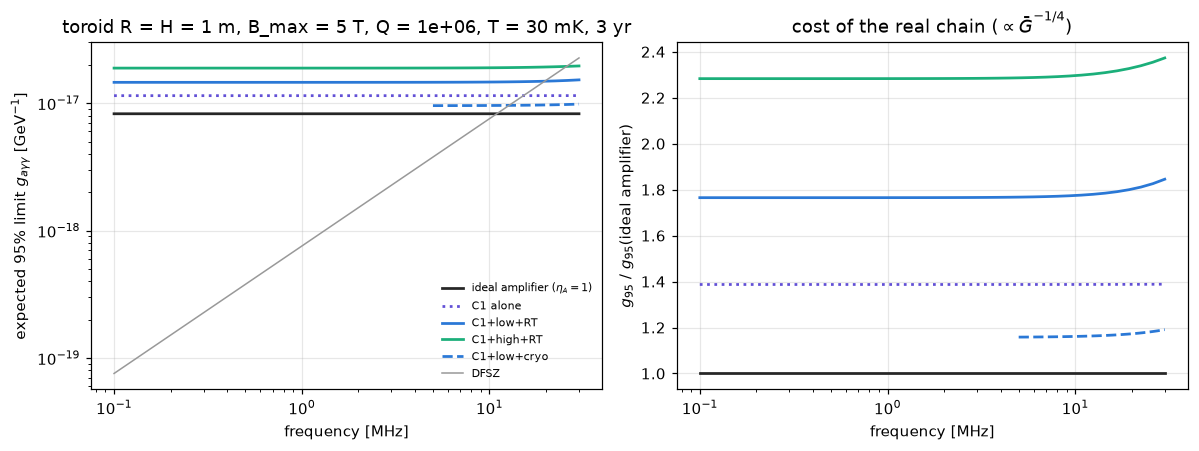

In [13]:
kw = dict(live_time_yr=3.0, allocation="log_uniform", n=40)
cases = [("ideal amplifier ($\\eta_A=1$)", {"Q": Q, "T": T, "eta_A": 1.0}, (1e5, 3e7), COL["ideal"], "-"),
         ("C1 alone", squid.benchmark("C1", Q, T), (1e5, 3e7), COL["C1"], ":"),
         ("C1+low+RT", squid.benchmark("C1+low+RT", Q, T), (1e5, 3e7), COL["low"], "-"),
         ("C1+high+RT", squid.benchmark("C1+high+RT", Q, T), (1e5, 3e7), COL["high"], "-"),
         ("C1+low+cryo", squid.benchmark("C1+low+cryo", Q, T), (5e6, 3e7), COL["low"], "--")]
reach = {name: scan.reach(PSI, LP, bm, f_min=a, f_max=b, **kw) for name, bm, (a, b), _, _ in cases}
ideal = reach[cases[0][0]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for name, bm, _, col, ls in cases:
    r = reach[name]
    axes[0].plot(r["f_Hz"] / 1e6, r["g95_GeV"], color=col, ls=ls, label=name)
    axes[1].plot(r["f_Hz"] / 1e6, r["g95_GeV"] / np.interp(np.log(r["f_Hz"]), np.log(ideal["f_Hz"]), ideal["g95_GeV"]),
                 color=col, ls=ls, label=name)
axes[0].plot(ideal["f_Hz"] / 1e6, ideal["g_target_GeV"], color="0.6", lw=1, label="DFSZ")
axes[0].set_yscale("log"); axes[0].set_ylabel(r"expected 95% limit $g_{a\gamma\gamma}$ [GeV$^{-1}$]")
axes[1].set_ylabel(r"$g_{95}$ / $g_{95}$(ideal amplifier)")
axes[0].set_title(f"toroid R = H = 1 m, B_max = {B_target:g} T, Q = {Q:.0e}, T = {T*1e3:.0f} mK, 3 yr")
axes[1].set_title(r"cost of the real chain ($\propto\bar G^{-1/4}$)")
for ax in axes:
    ax.set_xscale("log"); ax.set_xlabel("frequency [MHz]")
axes[0].legend(fontsize=7)
fig.tight_layout()

for name, *_ in cases:
    r = reach[name]
    print(f"{name.split(' (')[0]:<18} g95 at {r['f_Hz'][0]/1e6:5.2f} MHz = {r['g95_GeV'][0]:.3e} GeV^-1,  eta there = "
          f"{np.atleast_1d(r['band']['eta_A'])[0]:.2f}")

Lower axion-coupling limits mean better sensitivity; the right panel shows the penalty from amplifier noise.

## Correlation

We compare noise spectra for `sign=1`, `sign=-1` and zero correlation to assess how correlation affects sensitivity.

s = +1                       min N_V at x =  +103.4   int dw/N_V^2 = 3.2622e+61
s = -1                       min N_V at x =  -103.4   int dw/N_V^2 = 3.2619e+61
uncorrelated (S_PhiJ = 0)    min N_V at x =    +0.0   int dw/N_V^2 = 2.4258e+61


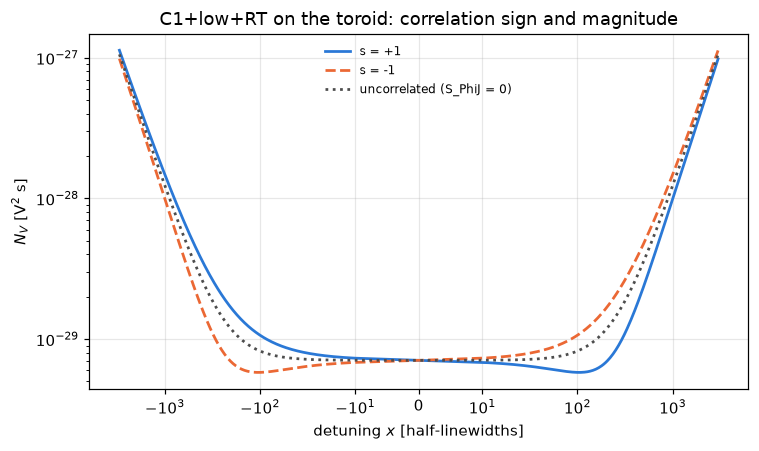

In [14]:
variants = {}
for s in (+1, -1):
    ro.squid = squid.chain("C1+low+RT", sign=s).squid_for_resonator(f0, QL, L_eff, T)
    variants[f"s = {s:+d}"] = budget(ro)["N_V_V2_s"]
ro.squid = dataclasses.replace(ro.squid, S_PhiJ=0.0)        # same S_Phi, S_J, correlation dropped
variants["uncorrelated (S_PhiJ = 0)"] = budget(ro)["N_V_V2_s"]

fig, ax = plt.subplots(figsize=(7, 4.2))
for (lab, N), col, ls in zip(variants.items(), ("#2a78d6", "#eb6834", "0.3"), ("-", "--", ":")):
    ax.plot(x, N, color=col, ls=ls, label=lab)
ax.set_xscale("symlog", linthresh=10.0, linscale=0.6); ax.set_yscale("log")
ax.set_xlabel(r"detuning $x$ [half-linewidths]"); ax.set_ylabel(r"$N_V$ [V$^2$ s]")
ax.set_title("C1+low+RT on the toroid: correlation sign and magnitude")
ax.legend(fontsize=8)
fig.tight_layout()

# information per tuning ~ integral of 1/N_V^2 over frequency (signal shape is flat across the band)
for lab, N in variants.items():
    print(f"{lab:<28} min N_V at x = {x[np.argmin(N)]:+7.1f}   int dw/N_V^2 = {np.trapezoid(N**-2, w):.4e}")

Reversing the sign shifts the noise minimum; removing correlation raises it.

We compare equivalent-circuit diagnostics for both signs and plot noise parameters with and without correlation to quantify its effect.

s = +1: eta_A_eff = 9.7075, eta uncorrelated = 12.4876, c = +7.855, x0 = +104.23, resid = 1.4e-04
s = -1: eta_A_eff = 9.7075, eta uncorrelated = 12.4876, c = -7.855, x0 = -104.23, resid = 1.4e-04


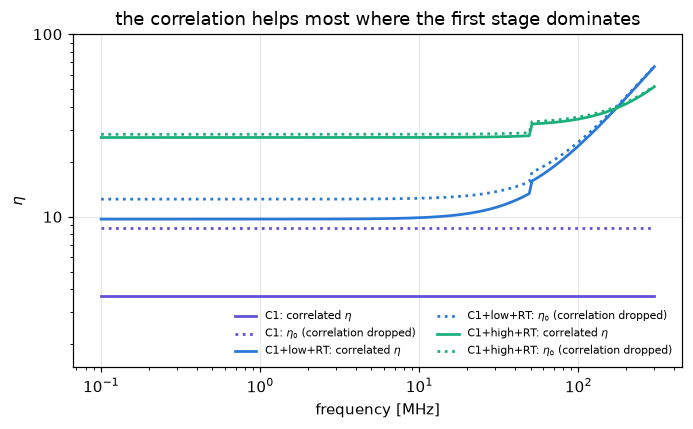

In [15]:
for s in (+1, -1):
    ro.squid = squid.chain("C1+low+RT", sign=s).squid_for_resonator(f0, QL, L_eff, T)
    e = ro.equivalent(w0)
    print(f"s = {s:+d}: eta_A_eff = {e['eta_A_eff']:.4f}, eta uncorrelated = {e['eta_A_eff_uncorrelated']:.4f}, "
          f"c = {e['correlation_c']:+.3f}, x0 = {e['band_shift_x0']:+.2f}, resid = {e['correlated_reduction_resid']:.1e}")

fe = np.geomspace(1e5, 3e8, 200)
fig, ax = plt.subplots(figsize=(6.4, 4))
for name, col in (("C1", COL["C1"]), ("C1+low+RT", COL["low"]), ("C1+high+RT", COL["high"])):
    ch = squid.chain(name)
    ax.plot(fe / 1e6, ch.eta(fe), color=col, label=f"{name}: correlated $\\eta$")
    ax.plot(fe / 1e6, ch.eta_uncorrelated(fe), color=col, ls=":", label=f"{name}: $\\eta_0$ (correlation dropped)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("frequency [MHz]"); ax.set_ylabel(r"$\eta$")
ax.set_ylim(1.5, 100)
ax.yaxis.set_major_formatter(plt.ScalarFormatter()); ax.yaxis.set_minor_formatter(plt.NullFormatter())
ax.set_title("the correlation helps most where the first stage dominates")
ax.legend(fontsize=7, ncol=2, loc="lower right")
fig.tight_layout()

A flux transformer can invalidate the single-pole reduction; we use the exact `noise_psd()` when `equivalent()` raises.

In [16]:
ft = ck.series_readout(L_p_H=1e-6, f_Hz=1e6, Q=1e6, T_K=0.03, L_1_H=1e-6, L_2_H=1e-6, L_in_H=1e-7,
                       k_T=math.sqrt(1.1e-6), M_H=1e-9)
ft.squid = squid.chain("C1", sign=+1).squid(1e6, 1e-9)
try:
    ft.equivalent(2 * math.pi * 1e6)
except ValueError as e:
    print("ValueError:", str(e)[:300], "...")
print("exact N_V on resonance is still available:", ft.noise_psd(2 * math.pi * 1e6)["N_V_V2_s"])

ValueError: Readout.equivalent: completed-square eta^2 = -36110.8 <= 0: the single-pole correlated reduction does not describe this network (reactive background between pickup and input coil); integrate the exact output noise instead (Readout.noise_psd, or MultiportReadout.output_snr_rate) ...
exact N_V on resonance is still available: 9.96887170392114e-30


## Circuit drawings

`axionfem[draw]` is required to display the schematics.

We draw the SQUID chain to show its stages.

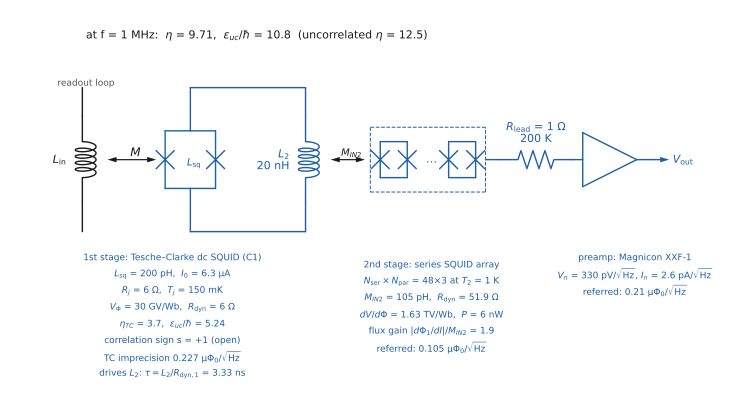

In [17]:
try:
    import schemdraw  # noqa: F401
    HAVE_SCHEMDRAW = True
except ImportError:
    HAVE_SCHEMDRAW = False
    print("schemdraw is not installed: pip install 'axionfem[draw]' to see the drawings")

if HAVE_SCHEMDRAW:
    display(squid.chain("C1+low+RT").draw(f_Hz=1e6))

We draw the tuned readout and check that the drawing matches the circuit model.

drawing vs circuit: exact


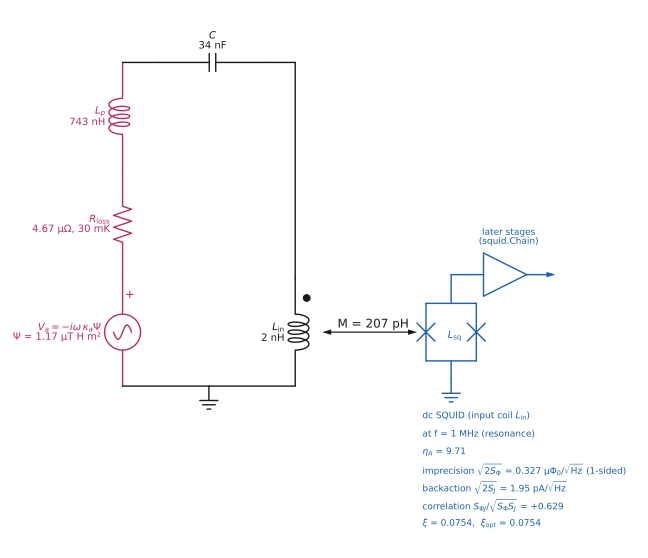

In [18]:
if HAVE_SCHEMDRAW:
    from axionfem.draw import check_drawing
    ro.squid = squid.chain("C1+low+RT", sign=+1).squid_for_resonator(f0, QL, L_eff, T)   # at resonance
    d = ro.draw()                      # values at the resonance
    print("drawing vs circuit:", check_drawing(d, ro.circuit) or "exact")
    display(d)

We draw the flux transformer to show its coupled loops.

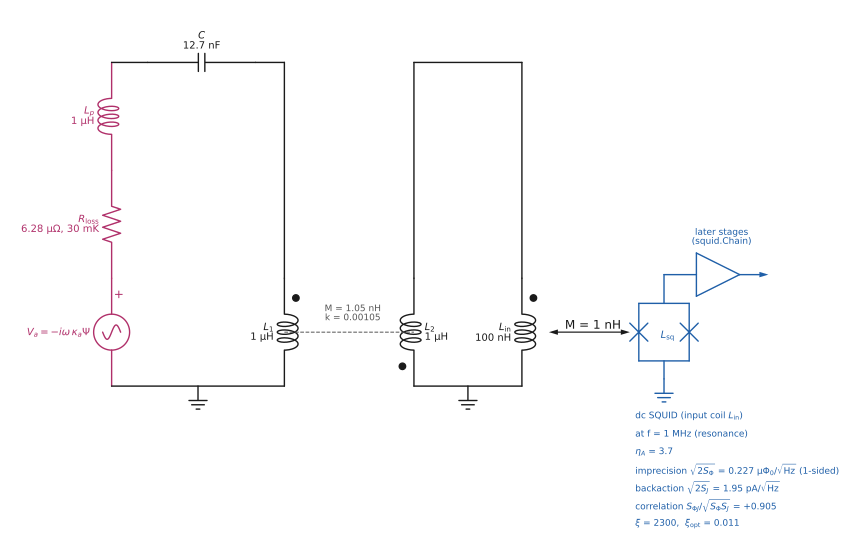

In [19]:
if HAVE_SCHEMDRAW:
    display(ft.draw())                 # the real flux transformer of the previous cell: two loops, k_T

Further reading: [Readout and multi-band scans](../docs/guides/readout_multiband.md) or the [API reference](../docs/api.md).